In [1]:
import nmrglue as ng
#import mat4py as mt
import pylab
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

data_types = ['A3DK08'] 
for data_type in data_types:
    dic,data = ng.pipe.read(f'./data/data_3D/{data_type}_label.ft1')
    udic = ng.varian.guess_udic(dic,data)
    print(udic)
    print(data.ndim)
    print(data.shape)
    print(data.dtype)
    sio.savemat(f'./data/data_3D/{data_type}_label.mat',{'data':data}, format='5')



{'ndim': 3, 0: {'sw': 999.99, 'complex': True, 'obs': 999.99, 'car': 999.99, 'size': 80, 'label': 'X', 'encoding': 'states', 'time': True, 'freq': False}, 1: {'sw': 999.99, 'complex': True, 'obs': 999.99, 'car': 999.99, 'size': 128, 'label': 'Y', 'encoding': 'states', 'time': True, 'freq': False}, 2: {'sw': 999.99, 'complex': True, 'obs': 999.99, 'car': 999.99, 'size': 512, 'label': 'Z', 'encoding': 'direct', 'time': True, 'freq': False}}
3
(80, 128, 512)
float32


In [2]:
import nmrglue as ng
import pylab
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

data_types = ['A3DK08'] 
for data_type in data_types:
    dic,data = ng.pipe.read(f'./data/data_3D/{data_type}_label.ft1')
    # dic,data = ng.pipe.read(f"F:/NMRPipe/ReadNMRData/az_HNCA_high_res/az_HNCA_high_res.fid/azurin_hyper.ft1")
    # data = np.transpose(data,axes=(2, 0, 1))
    udic = ng.varian.guess_udic(dic,data)
    print(udic)
    #
    print(data.ndim)
    print(data.shape)
    print(data.dtype)


    sio.savemat(f'./data/data_3D/{data_type}_label.mat',{'data':data}, format='5')



{'ndim': 3, 0: {'sw': 999.99, 'complex': True, 'obs': 999.99, 'car': 999.99, 'size': 80, 'label': 'X', 'encoding': 'states', 'time': True, 'freq': False}, 1: {'sw': 999.99, 'complex': True, 'obs': 999.99, 'car': 999.99, 'size': 128, 'label': 'Y', 'encoding': 'states', 'time': True, 'freq': False}, 2: {'sw': 999.99, 'complex': True, 'obs': 999.99, 'car': 999.99, 'size': 512, 'label': 'Z', 'encoding': 'direct', 'time': True, 'freq': False}}
3
(80, 128, 512)
float32


[ 0  2  4  6  8 10 12 14 16 18 20 22 24 26 28 30 32 34 36 38 40 42 44 46
 48 50 52 54 56 58 60 62 64 66 68 70 72 74 76 78]


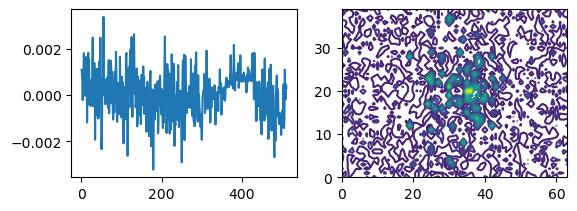

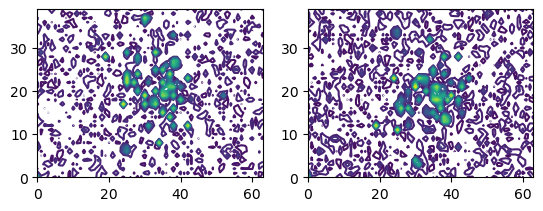

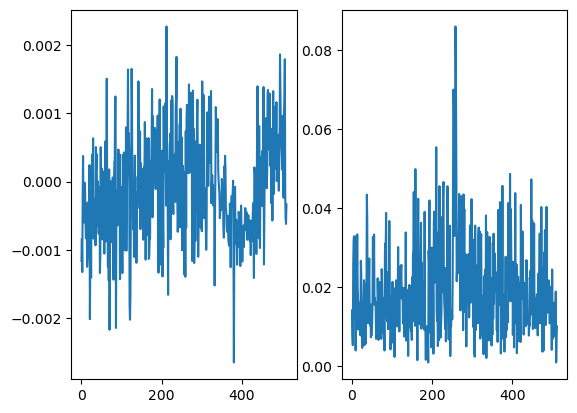

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import nmrglue as ng
import os
import scipy.io as sio

data_types = ['A3DK08'] # 'A3DK08','PSRP','mousethia','Ecolinird','Ykvr','Altg','Yorp'

for data_type in data_types:
    data = sio.loadmat(f'./data/data_3D/{data_type}_label.mat')['data']
    N1 = data.shape[0]
    N2 = data.shape[1]
    N3 = data.shape[2]
    # print(N1,N2,N3)

    r1 = np.arange(0, N1, 2)
    i1 = np.arange(1, N1, 2)
    r2 = np.arange(0, N2, 2)
    i2 = np.arange(1, N2, 2)
    print(r1)

    Rr = data[np.ix_(r1, r2)]
    Ri = data[np.ix_(r1, i2)]
    Ir = data[np.ix_(i1, r2)]
    Ii = data[np.ix_(i1, i2)]

    fid1 = Rr + 1j*Ri #Rc cos(w1*t1)*exp(1i*w2*t2)
    fid2 = Ir + 1j*Ii #Ic sin(w1*t1)*exp(1i*w2*t2)

    fid_r1 = fid1+1j*fid2                               
    fid_r2 = fid1-1j*fid2 


    # sio.savemat(f'A3DK08.mat',{'Xr':fid1,'Xi':fid2})
    sio.savemat(f'./data/data_3D/{data_type}_r.mat', {'data': fid_r1})
    sio.savemat(f'./data/data_3D/{data_type}_i.mat', {'data': fid_r2})
 

    spec1 = np.zeros((N1//2,N2//2,N3), dtype=complex)
    spec2 = np.zeros((N1//2,N2//2,N3), dtype=complex)
    for i in range(N3):
        spec1[:,:,i] = np.fft.fft2(fid1[:,:,i])
        spec2[:,:,i] = np.fft.fft2(fid2[:,:,i])
    plt.figure()
    plt.subplot(221)
    plt.plot(np.squeeze(np.real(fid_r1[1,1,:])))
    plt.subplot(222)
    plt.contour(np.max(np.abs(spec2),axis=2),cmap='viridis',levels=21)
    plt.show()

    for i in range(N3):
        spec1[:,:,i] = np.fft.fft2(fid_r1[:,:,i])
        spec2[:,:,i] = np.fft.fft2(fid_r2[:,:,i])
    plt.figure()
    plt.subplot(221)
    plt.contour(np.max(np.abs(spec1),axis=2),cmap='viridis',levels=21)
    plt.subplot(222)
    plt.contour(np.max(np.abs(spec2),axis=2),cmap='viridis',levels=21)
    plt.show()

    plt.figure()
    plt.subplot(1,2,1)
    plt.plot(np.squeeze(np.real(fid1[1,0,:])))
    plt.subplot(1,2,2)
    plt.plot(np.squeeze(np.abs(np.fft.fftshift(np.fft.fft(fid1[1,0,:].squeeze())))))
    plt.show()

In [4]:
import os
import numpy as np
from scipy.io import loadmat, savemat
from scipy.fftpack import fft, fftshift

data = loadmat('./data/data_3D/A3DK08_r.mat')
spec1 = data['data']

spec1 = fft(spec1, axis=0)
spec1 = fft(spec1, axis=1)
spec1 = fftshift(spec1, axes=(0, 1))

third_dim_size = spec1.shape[2]

folder_name = 'data/data_3D/data64/A3DK08_r_slices'
os.makedirs(folder_name, exist_ok=True)

for i in range(third_dim_size):
    spec = spec1[:, :, i]

    filename = f'label_spec{i+1}.mat'
    filepath = os.path.join(folder_name, filename)

    savemat(filepath, {'spec': spec})


In [5]:
import os
import numpy as np
from scipy.io import loadmat, savemat
from scipy.fftpack import fft, fftshift

data = loadmat('./data/data_3D/A3DK08_i.mat')
spec1 = data['data']

spec1 = fft(spec1, axis=0)
spec1 = fft(spec1, axis=1)
spec1 = fftshift(spec1, axes=(0, 1))

third_dim_size = spec1.shape[2]

folder_name = 'data/data_3D/data64/A3DK08_i_slices'
os.makedirs(folder_name, exist_ok=True)

for i in range(third_dim_size):
    spec = spec1[:, :, i]

    filename = f'label_spec{i+1}.mat'
    filepath = os.path.join(folder_name, filename)

    savemat(filepath, {'spec': spec})


In [ ]:
import os
import re
import random
import traceback

import numpy as np
import scipy.io as scio
import torch

# =========================
# 1) Build val_data only
# =========================
DATA_ROOT = './data/data_3D/data64'
DATA_NAME = 'A3DK08_r'   # Change to 'A3DK08_i' and rerun this cell if you want the anti-echo branch.
MASK_SOURCE_DIR = '/mnt/DATA1/shaojie/code/mask/0.08_2D_mask-40-64'
MASK_POOL_SIZE = 1000
BLOCK_SIZE = 64

# Optional: set to a list like [1, 2, 3] for quick tests. None means all label_spec*.mat files.
SEQUENCE_LIST = None

NUS_SCALE = 4.0
HR_SCALE = 4.0
RANDOM_SEED = 60
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


def pad_data(data, block_size):
    height, width = data.shape
    pad_height = (block_size - height % block_size) % block_size
    pad_width = (block_size - width % block_size) % block_size
    padded_data = np.pad(data, ((0, pad_height), (0, pad_width)), mode='constant', constant_values=0)
    return padded_data, pad_height, pad_width



def block_data(data, block_size):
    padded_data, pad_height, pad_width = pad_data(data, block_size)
    height, width = padded_data.shape
    num_blocks_vertical = height // block_size
    num_blocks_horizontal = width // block_size
    blocks = np.empty((num_blocks_vertical * num_blocks_horizontal, block_size, block_size), dtype=padded_data.dtype)
    idx = 0
    for i in range(num_blocks_vertical):
        for j in range(num_blocks_horizontal):
            block = padded_data[i*block_size:(i+1)*block_size, j*block_size:(j+1)*block_size]
            blocks[idx] = block
            idx += 1
    return blocks, padded_data.shape, pad_height, pad_width



def reconstruct_data(blocks, pad_shape, pad_height, pad_width):
    height, width = pad_shape
    num_blocks, block_height, block_width = blocks.shape
    num_blocks_vertical = height // block_height
    num_blocks_horizontal = width // block_width
    reconstructed_data = np.empty((height, width), dtype=blocks.dtype)
    idx = 0
    for i in range(num_blocks_vertical):
        for j in range(num_blocks_horizontal):
            block = blocks[idx]
            reconstructed_data[i*block_height:(i+1)*block_height, j*block_width:(j+1)*block_width] = block
            idx += 1
    final_data = reconstructed_data[:height if not pad_height else -pad_height, :width if not pad_width else -pad_width]
    return final_data



def load_mask(mask_path):
    mask_data = scio.loadmat(mask_path)
    if 'Mask' in mask_data:
        return mask_data['Mask']
    if 'mask' in mask_data:
        return mask_data['mask']
    if 'MASK' in mask_data:
        return mask_data['MASK']

    valid_keys = [k for k in mask_data.keys() if not k.startswith('__')]
    if not valid_keys:
        raise KeyError(f'No valid mask variable found in {mask_path}')
    return mask_data[valid_keys[0]]



def find_mask_files(mask_dir, pool_size):
    if not os.path.isdir(mask_dir):
        raise FileNotFoundError(f'Mask directory not found: {mask_dir}')

    mask_files = []
    pattern = re.compile(r'[Mm][Aa][Ss][Kk]_(\d+)\.mat$')
    for filename in os.listdir(mask_dir):
        match = pattern.match(filename)
        if match:
            mask_files.append((int(match.group(1)), os.path.join(mask_dir, filename)))

    mask_files = [path for _, path in sorted(mask_files, key=lambda item: item[0])]
    mask_files = mask_files[:pool_size]

    if len(mask_files) < pool_size:
        raise FileNotFoundError(
            f'Only found {len(mask_files)} masks in {mask_dir}, expected {pool_size}'
        )

    return mask_files


def find_sequences(slice_dir):
    if SEQUENCE_LIST is not None:
        return list(SEQUENCE_LIST)

    sequences = []
    pattern = re.compile(r'label_spec(\d+)\.mat$')
    for filename in os.listdir(slice_dir):
        match = pattern.match(filename)
        if match:
            sequences.append(int(match.group(1)))
    return sorted(sequences)


def prepare_one_sequence(sequence):
    data_path = f'{DATA_ROOT}/{DATA_NAME}_slices/label_spec{sequence}.mat'
    mat = scio.loadmat(data_path)
    if 'spec' not in mat:
        raise KeyError(f'{data_path} does not contain variable "spec"')

    ori_spec = mat['spec'].astype(np.complex64)
    n1, n2 = ori_spec.shape

    threshold = 0.01
    amp_max = np.max(np.abs(ori_spec), axis=1, keepdims=True)
    ori_spec = ori_spec.copy()
    ori_spec[np.abs(ori_spec) < amp_max * threshold] = 0

    full_fid = np.fft.ifft2(ori_spec)

    mask_path = random.choice(MASK_FILES)
    sampled_mask = load_mask(mask_path).astype(np.float32)
    if sampled_mask.shape != (n1, n2):
        raise ValueError(
            f'Mask shape {sampled_mask.shape} does not match original slice shape {(n1, n2)}'
        )

    # Match take_sample3D: apply the NUS mask on the original-size FID,
    # then pad/block the sampled FID and spectra for the 256x256 denoiser.
    nus_fid = sampled_mask * full_fid
    noise_input = np.fft.fft2(nus_fid)
    gt_label = np.fft.fft2(full_fid)
    original_shape = (n1, n2)

    nus_fid_blocks, pad_shape, pad_height, pad_width = block_data(nus_fid, BLOCK_SIZE)
    noise_input_blocks, _, _, _ = block_data(noise_input, BLOCK_SIZE)
    gt_label_blocks, _, _, _ = block_data(gt_label, BLOCK_SIZE)

    max_amp = np.max(np.abs(noise_input_blocks))
    if max_amp == 0:
        raise ValueError(f'Zero max amplitude in sequence {sequence}')

    nus_fid_tensor = torch.complex(
        torch.from_numpy(nus_fid_blocks.real).float(),
        torch.from_numpy(nus_fid_blocks.imag).float()
    ) / (max_amp * NUS_SCALE)

    noise_input_tensor = torch.complex(
        torch.from_numpy(noise_input_blocks.real).float(),
        torch.from_numpy(noise_input_blocks.imag).float()
    ) / max_amp

    gt_label_tensor = torch.complex(
        torch.from_numpy(gt_label_blocks.real).float(),
        torch.from_numpy(gt_label_blocks.imag).float()
    ) / (max_amp * HR_SCALE)

    lr = nus_fid_tensor.unsqueeze(1)
    sr = torch.cat(
        (noise_input_tensor.real.unsqueeze(1), noise_input_tensor.imag.unsqueeze(1)),
        dim=1
    )
    hr = torch.cat(
        (gt_label_tensor.real.unsqueeze(1), gt_label_tensor.imag.unsqueeze(1)),
        dim=1
    )

    return lr, sr, hr, {
        'sequence': int(sequence),
        'block_num': int(gt_label_blocks.shape[0]),
        'pad_shape': (int(pad_shape[0]), int(pad_shape[1])),
        'pad_height': int(pad_height),
        'pad_width': int(pad_width),
        'max_amp': float(max_amp),
        'original_shape': original_shape,
        'data_path': data_path,
        'mask_path': mask_path,
    }


slice_dir = f'{DATA_ROOT}/{DATA_NAME}_slices'
if not os.path.isdir(slice_dir):
    raise FileNotFoundError(f'Slice directory not found: {slice_dir}')

sequences = find_sequences(slice_dir)
if not sequences:
    raise FileNotFoundError(f'No label_spec*.mat files found in {slice_dir}')

MASK_FILES = find_mask_files(MASK_SOURCE_DIR, MASK_POOL_SIZE)
print(f'Using {len(MASK_FILES)} masks from {MASK_SOURCE_DIR}')
print(f'First mask: {os.path.basename(MASK_FILES[0])}, last mask: {os.path.basename(MASK_FILES[-1])}')

lr_list = []
sr_list = []
hr_list = []
sequence_meta = []
cursor = 0

for sequence in sequences:
    try:
        lr, sr, hr, meta = prepare_one_sequence(sequence)
        meta['start'] = cursor
        meta['end'] = cursor + meta['block_num']
        cursor = meta['end']

        lr_list.append(lr)
        sr_list.append(sr)
        hr_list.append(hr)
        sequence_meta.append(meta)
        print(
            f'Prepared {DATA_NAME} sequence {sequence}: '
            f'blocks={meta["block_num"]}, '
            f'pad_shape={meta["pad_shape"]}, '
            f'pad_height={meta["pad_height"]}, '
            f'pad_width={meta["pad_width"]}, '
            f'original_shape={meta["original_shape"]}, '
            f'mask={os.path.basename(meta["mask_path"])}'
        )
    except Exception as e:
        print(f'Prepare failed for sequence {sequence}: {e}')
        traceback.print_exc()

if not lr_list:
    raise RuntimeError('No valid sequence was prepared.')

val_data = {
    'LR': torch.cat(lr_list, dim=0),
    'SR': torch.cat(sr_list, dim=0),
    'HR': torch.cat(hr_list, dim=0),
}

total_blocks = cursor




In [ ]:
import argparse
import gc
import os
import time

import matplotlib.pyplot as plt
import scipy.io as scio
import torch

import core.logger as Logger
import core.metrics as Metrics
import model as Model

# =========================
# 2) Model test / PnP reconstruction only
# =========================
# Keep this small to avoid CUDA OOM. Increase to 2/4/8 only after confirming memory is safe.
INFER_SEQUENCE_BATCH_SIZE = 64

parser = argparse.ArgumentParser()
parser.add_argument(
    '-c', '--config',
    type=str,
    default='config/sr_sr3_64_64.json',
    help='JSON file for configuration'
)
parser.add_argument('-p', '--phase', type=str, choices=['train', 'val'], default='val')
parser.add_argument('-gpu', '--gpu_ids', type=str, default=None)
parser.add_argument('-debug', '-d', action='store_true')
parser.add_argument('-enable_wandb', action='store_true')
parser.add_argument('-log_wandb_ckpt', action='store_true')
parser.add_argument('-log_eval', action='store_true')

args = parser.parse_args(args=[])
opt = Logger.parse(args)
opt = Logger.dict_to_nonedict(opt)

torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark = True

result_dir = f'./data/data_3D/{DATA_NAME}_recon'
os.makedirs(result_dir, exist_ok=True)

if 'val_data' not in globals():
    raise RuntimeError('val_data is missing. Run the previous Build val_data cell first.')
if 'sequence_meta' not in globals() or len(sequence_meta) == 0:
    raise RuntimeError('sequence_meta is empty. Run the previous Build val_data cell and make sure slices were prepared.')
if 'total_blocks' not in globals() or total_blocks <= 0:
    raise RuntimeError('total_blocks is missing or zero. Run the previous Build val_data cell first.')

print('DATA_NAME:', DATA_NAME)
print('result_dir:', result_dir)
print('num_sequences:', len(sequence_meta))
print('total_blocks:', total_blocks)
print('infer sequence batch size:', INFER_SEQUENCE_BATCH_SIZE)
print('LR:', tuple(val_data['LR'].shape), val_data['LR'].dtype)
print('SR:', tuple(val_data['SR'].shape), val_data['SR'].dtype)
print('HR:', tuple(val_data['HR'].shape), val_data['HR'].dtype)
print('first_meta:', sequence_meta[0])

diffusion = Model.create_model(opt)
if opt['model'].get('beta_schedule') is not None:
    diffusion.set_new_noise_schedule(
        opt['model']['beta_schedule']['val'],
        schedule_phase='val'
    )


def iter_meta_batches(meta_list, batch_size):
    for start_idx in range(0, len(meta_list), batch_size):
        yield meta_list[start_idx:start_idx + batch_size]


start_time = time.time()
processed_sequences = 0

for meta_batch in iter_meta_batches(sequence_meta, INFER_SEQUENCE_BATCH_SIZE):
    batch_start = min(meta['start'] for meta in meta_batch)
    batch_end = max(meta['end'] for meta in meta_batch)
    batch_total_blocks = batch_end - batch_start
    batch_sequences = [meta['sequence'] for meta in meta_batch]

    print(f'[Batch] sequence={batch_sequences}, total_blocks={batch_total_blocks}')

    val_data_batch = {
        'LR': val_data['LR'][batch_start:batch_end],
        'SR': val_data['SR'][batch_start:batch_end],
        'HR': val_data['HR'][batch_start:batch_end],
    }

    val_data_device = diffusion.set_device(val_data_batch)
    diffusion.feed_data(val_data_device)
    diffusion.test(continous=False, pnp_mode='nus_slice_64')

    visuals = diffusion.get_current_visuals()
    sr_final = visuals['SR'][-batch_total_blocks:]

    for meta in meta_batch:
        local_start = meta['start'] - batch_start
        local_end = meta['end'] - batch_start
        sequence = meta['sequence']
        pad_shape = meta['pad_shape']
        pad_height = meta['pad_height']
        pad_width = meta['pad_width']
        max_amp = meta['max_amp']

        input_spec = reconstruct_data(
            torch.complex(
                visuals['INF'][local_start:local_end, 0],
                visuals['INF'][local_start:local_end, 1]
            ).cpu().numpy(),
            pad_shape,
            pad_height,
            pad_width
        ) * max_amp

        recon_spec = reconstruct_data(
            torch.complex(
                sr_final[local_start:local_end, 0],
                sr_final[local_start:local_end, 1]
            ).cpu().numpy(),
            pad_shape,
            pad_height,
            pad_width
        ) * (max_amp * HR_SCALE)

        label_spec = reconstruct_data(
            torch.complex(
                visuals['HR'][local_start:local_end, 0],
                visuals['HR'][local_start:local_end, 1]
            ).cpu().numpy(),
            pad_shape,
            pad_height,
            pad_width
        ) * (max_amp * HR_SCALE)

        scio.savemat(f'{result_dir}/input_spec{sequence}.mat', {'input_spec': input_spec})
        scio.savemat(f'{result_dir}/recon_spec{sequence}.mat', {'recon_spec': recon_spec})
        scio.savemat(f'{result_dir}/label_spec{sequence}.mat', {'label_spec': label_spec})

        try:
            Metrics.plot_contour(
                nus_spec=input_spec,
                recon_spec=recon_spec,
                label_spec=label_spec,
                fig_num=sequence
            )
            plt.savefig(f'{result_dir}/contour_{sequence}.png', dpi=200)
            plt.close('all')
        except Exception as e:
            print(f'Plot failed for sequence {sequence}: {e}')

        processed_sequences += 1

    del val_data_batch, val_data_device, visuals, sr_final
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()

elapsed = time.time() - start_time
saved_files = [name for name in os.listdir(result_dir) if name.endswith(('.mat', '.png'))]



In [ ]:
import os
import re
import random
import traceback

import numpy as np
import scipy.io as scio
import torch

# =========================
# 1) Build val_data only
# =========================
DATA_ROOT = './data/data_3D/data64'
DATA_NAME = 'A3DK08_i'   # Change to 'A3DK08_i' and rerun this cell if you want the anti-echo branch.
MASK_SOURCE_DIR = '/mnt/DATA1/shaojie/code/data/0.08_2D_mask-40-64'
MASK_POOL_SIZE = 1000
BLOCK_SIZE = 64

# Optional: set to a list like [1, 2, 3] for quick tests. None means all label_spec*.mat files.
SEQUENCE_LIST = None

NUS_SCALE = 4.0
HR_SCALE = 4.0
RANDOM_SEED = 60
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


def pad_data(data, block_size):
    height, width = data.shape
    pad_height = (block_size - height % block_size) % block_size
    pad_width = (block_size - width % block_size) % block_size
    padded_data = np.pad(data, ((0, pad_height), (0, pad_width)), mode='constant', constant_values=0)
    return padded_data, pad_height, pad_width



def block_data(data, block_size):
    padded_data, pad_height, pad_width = pad_data(data, block_size)
    height, width = padded_data.shape
    num_blocks_vertical = height // block_size
    num_blocks_horizontal = width // block_size
    blocks = np.empty((num_blocks_vertical * num_blocks_horizontal, block_size, block_size), dtype=padded_data.dtype)
    idx = 0
    for i in range(num_blocks_vertical):
        for j in range(num_blocks_horizontal):
            block = padded_data[i*block_size:(i+1)*block_size, j*block_size:(j+1)*block_size]
            blocks[idx] = block
            idx += 1
    return blocks, padded_data.shape, pad_height, pad_width



def reconstruct_data(blocks, pad_shape, pad_height, pad_width):
    height, width = pad_shape
    num_blocks, block_height, block_width = blocks.shape
    num_blocks_vertical = height // block_height
    num_blocks_horizontal = width // block_width
    reconstructed_data = np.empty((height, width), dtype=blocks.dtype)
    idx = 0
    for i in range(num_blocks_vertical):
        for j in range(num_blocks_horizontal):
            block = blocks[idx]
            reconstructed_data[i*block_height:(i+1)*block_height, j*block_width:(j+1)*block_width] = block
            idx += 1
    final_data = reconstructed_data[:height if not pad_height else -pad_height, :width if not pad_width else -pad_width]
    return final_data



def load_mask(mask_path):
    mask_data = scio.loadmat(mask_path)
    if 'Mask' in mask_data:
        return mask_data['Mask']
    if 'mask' in mask_data:
        return mask_data['mask']
    if 'MASK' in mask_data:
        return mask_data['MASK']

    valid_keys = [k for k in mask_data.keys() if not k.startswith('__')]
    if not valid_keys:
        raise KeyError(f'No valid mask variable found in {mask_path}')
    return mask_data[valid_keys[0]]



def find_mask_files(mask_dir, pool_size):
    if not os.path.isdir(mask_dir):
        raise FileNotFoundError(f'Mask directory not found: {mask_dir}')

    mask_files = []
    pattern = re.compile(r'[Mm][Aa][Ss][Kk]_(\d+)\.mat$')
    for filename in os.listdir(mask_dir):
        match = pattern.match(filename)
        if match:
            mask_files.append((int(match.group(1)), os.path.join(mask_dir, filename)))

    mask_files = [path for _, path in sorted(mask_files, key=lambda item: item[0])]
    mask_files = mask_files[:pool_size]

    if len(mask_files) < pool_size:
        raise FileNotFoundError(
            f'Only found {len(mask_files)} masks in {mask_dir}, expected {pool_size}'
        )

    return mask_files


def find_sequences(slice_dir):
    if SEQUENCE_LIST is not None:
        return list(SEQUENCE_LIST)

    sequences = []
    pattern = re.compile(r'label_spec(\d+)\.mat$')
    for filename in os.listdir(slice_dir):
        match = pattern.match(filename)
        if match:
            sequences.append(int(match.group(1)))
    return sorted(sequences)


def prepare_one_sequence(sequence):
    data_path = f'{DATA_ROOT}/{DATA_NAME}_slices/label_spec{sequence}.mat'
    mat = scio.loadmat(data_path)
    if 'spec' not in mat:
        raise KeyError(f'{data_path} does not contain variable "spec"')

    ori_spec = mat['spec'].astype(np.complex64)
    n1, n2 = ori_spec.shape

    threshold = 0.01
    amp_max = np.max(np.abs(ori_spec), axis=1, keepdims=True)
    ori_spec = ori_spec.copy()
    ori_spec[np.abs(ori_spec) < amp_max * threshold] = 0

    full_fid = np.fft.ifft2(ori_spec)

    mask_path = random.choice(MASK_FILES)
    sampled_mask = load_mask(mask_path).astype(np.float32)
    if sampled_mask.shape != (n1, n2):
        raise ValueError(
            f'Mask shape {sampled_mask.shape} does not match original slice shape {(n1, n2)}'
        )

    # Match take_sample3D: apply the NUS mask on the original-size FID,
    # then pad/block the sampled FID and spectra for the 256x256 denoiser.
    nus_fid = sampled_mask * full_fid
    noise_input = np.fft.fft2(nus_fid)
    gt_label = np.fft.fft2(full_fid)
    original_shape = (n1, n2)

    nus_fid_blocks, pad_shape, pad_height, pad_width = block_data(nus_fid, BLOCK_SIZE)
    noise_input_blocks, _, _, _ = block_data(noise_input, BLOCK_SIZE)
    gt_label_blocks, _, _, _ = block_data(gt_label, BLOCK_SIZE)

    max_amp = np.max(np.abs(noise_input_blocks))
    if max_amp == 0:
        raise ValueError(f'Zero max amplitude in sequence {sequence}')

    nus_fid_tensor = torch.complex(
        torch.from_numpy(nus_fid_blocks.real).float(),
        torch.from_numpy(nus_fid_blocks.imag).float()
    ) / (max_amp * NUS_SCALE)

    noise_input_tensor = torch.complex(
        torch.from_numpy(noise_input_blocks.real).float(),
        torch.from_numpy(noise_input_blocks.imag).float()
    ) / max_amp

    gt_label_tensor = torch.complex(
        torch.from_numpy(gt_label_blocks.real).float(),
        torch.from_numpy(gt_label_blocks.imag).float()
    ) / (max_amp * HR_SCALE)

    lr = nus_fid_tensor.unsqueeze(1)
    sr = torch.cat(
        (noise_input_tensor.real.unsqueeze(1), noise_input_tensor.imag.unsqueeze(1)),
        dim=1
    )
    hr = torch.cat(
        (gt_label_tensor.real.unsqueeze(1), gt_label_tensor.imag.unsqueeze(1)),
        dim=1
    )

    return lr, sr, hr, {
        'sequence': int(sequence),
        'block_num': int(gt_label_blocks.shape[0]),
        'pad_shape': (int(pad_shape[0]), int(pad_shape[1])),
        'pad_height': int(pad_height),
        'pad_width': int(pad_width),
        'max_amp': float(max_amp),
        'original_shape': original_shape,
        'data_path': data_path,
        'mask_path': mask_path,
    }


slice_dir = f'{DATA_ROOT}/{DATA_NAME}_slices'
if not os.path.isdir(slice_dir):
    raise FileNotFoundError(f'Slice directory not found: {slice_dir}')

sequences = find_sequences(slice_dir)
if not sequences:
    raise FileNotFoundError(f'No label_spec*.mat files found in {slice_dir}')

MASK_FILES = find_mask_files(MASK_SOURCE_DIR, MASK_POOL_SIZE)
print(f'Using {len(MASK_FILES)} masks from {MASK_SOURCE_DIR}')
print(f'First mask: {os.path.basename(MASK_FILES[0])}, last mask: {os.path.basename(MASK_FILES[-1])}')

lr_list = []
sr_list = []
hr_list = []
sequence_meta = []
cursor = 0

for sequence in sequences:
    try:
        lr, sr, hr, meta = prepare_one_sequence(sequence)
        meta['start'] = cursor
        meta['end'] = cursor + meta['block_num']
        cursor = meta['end']

        lr_list.append(lr)
        sr_list.append(sr)
        hr_list.append(hr)
        sequence_meta.append(meta)
        print(
            f'Prepared {DATA_NAME} sequence {sequence}: '
            f'blocks={meta["block_num"]}, '
            f'pad_shape={meta["pad_shape"]}, '
            f'pad_height={meta["pad_height"]}, '
            f'pad_width={meta["pad_width"]}, '
            f'original_shape={meta["original_shape"]}, '
            f'mask={os.path.basename(meta["mask_path"])}'
        )
    except Exception as e:
        print(f'Prepare failed for sequence {sequence}: {e}')
        traceback.print_exc()

if not lr_list:
    raise RuntimeError('No valid sequence was prepared.')

val_data = {
    'LR': torch.cat(lr_list, dim=0),
    'SR': torch.cat(sr_list, dim=0),
    'HR': torch.cat(hr_list, dim=0),
}

total_blocks = cursor




In [ ]:
import argparse
import gc
import os
import time

import matplotlib.pyplot as plt
import scipy.io as scio
import torch

import core.logger as Logger
import core.metrics as Metrics
import model as Model

# =========================
# 2) Model test / PnP reconstruction only
# =========================
# Keep this small to avoid CUDA OOM. Increase to 2/4/8 only after confirming memory is safe.
INFER_SEQUENCE_BATCH_SIZE = 64

parser = argparse.ArgumentParser()
parser.add_argument(
    '-c', '--config',
    type=str,
    default='config/sr_sr3_64_64.json',
    help='JSON file for configuration'
)
parser.add_argument('-p', '--phase', type=str, choices=['train', 'val'], default='val')
parser.add_argument('-gpu', '--gpu_ids', type=str, default=None)
parser.add_argument('-debug', '-d', action='store_true')
parser.add_argument('-enable_wandb', action='store_true')
parser.add_argument('-log_wandb_ckpt', action='store_true')
parser.add_argument('-log_eval', action='store_true')

args = parser.parse_args(args=[])
opt = Logger.parse(args)
opt = Logger.dict_to_nonedict(opt)

torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark = True

result_dir = f'./data/data_3D/{DATA_NAME}_recon'
os.makedirs(result_dir, exist_ok=True)

if 'val_data' not in globals():
    raise RuntimeError('val_data is missing. Run the previous Build val_data cell first.')
if 'sequence_meta' not in globals() or len(sequence_meta) == 0:
    raise RuntimeError('sequence_meta is empty. Run the previous Build val_data cell and make sure slices were prepared.')
if 'total_blocks' not in globals() or total_blocks <= 0:
    raise RuntimeError('total_blocks is missing or zero. Run the previous Build val_data cell first.')

print('DATA_NAME:', DATA_NAME)
print('result_dir:', result_dir)
print('num_sequences:', len(sequence_meta))
print('total_blocks:', total_blocks)
print('infer sequence batch size:', INFER_SEQUENCE_BATCH_SIZE)
print('LR:', tuple(val_data['LR'].shape), val_data['LR'].dtype)
print('SR:', tuple(val_data['SR'].shape), val_data['SR'].dtype)
print('HR:', tuple(val_data['HR'].shape), val_data['HR'].dtype)
print('first_meta:', sequence_meta[0])

diffusion = Model.create_model(opt)
if opt['model'].get('beta_schedule') is not None:
    diffusion.set_new_noise_schedule(
        opt['model']['beta_schedule']['val'],
        schedule_phase='val'
    )


def iter_meta_batches(meta_list, batch_size):
    for start_idx in range(0, len(meta_list), batch_size):
        yield meta_list[start_idx:start_idx + batch_size]


start_time = time.time()
processed_sequences = 0

for meta_batch in iter_meta_batches(sequence_meta, INFER_SEQUENCE_BATCH_SIZE):
    batch_start = min(meta['start'] for meta in meta_batch)
    batch_end = max(meta['end'] for meta in meta_batch)
    batch_total_blocks = batch_end - batch_start
    batch_sequences = [meta['sequence'] for meta in meta_batch]

    print(f'[Batch] sequence={batch_sequences}, total_blocks={batch_total_blocks}')

    val_data_batch = {
        'LR': val_data['LR'][batch_start:batch_end],
        'SR': val_data['SR'][batch_start:batch_end],
        'HR': val_data['HR'][batch_start:batch_end],
    }

    val_data_device = diffusion.set_device(val_data_batch)
    diffusion.feed_data(val_data_device)
    diffusion.test(continous=False, pnp_mode='nus_slice_64')

    visuals = diffusion.get_current_visuals()
    sr_final = visuals['SR'][-batch_total_blocks:]

    for meta in meta_batch:
        local_start = meta['start'] - batch_start
        local_end = meta['end'] - batch_start
        sequence = meta['sequence']
        pad_shape = meta['pad_shape']
        pad_height = meta['pad_height']
        pad_width = meta['pad_width']
        max_amp = meta['max_amp']

        input_spec = reconstruct_data(
            torch.complex(
                visuals['INF'][local_start:local_end, 0],
                visuals['INF'][local_start:local_end, 1]
            ).cpu().numpy(),
            pad_shape,
            pad_height,
            pad_width
        ) * max_amp

        recon_spec = reconstruct_data(
            torch.complex(
                sr_final[local_start:local_end, 0],
                sr_final[local_start:local_end, 1]
            ).cpu().numpy(),
            pad_shape,
            pad_height,
            pad_width
        ) * (max_amp * HR_SCALE)

        label_spec = reconstruct_data(
            torch.complex(
                visuals['HR'][local_start:local_end, 0],
                visuals['HR'][local_start:local_end, 1]
            ).cpu().numpy(),
            pad_shape,
            pad_height,
            pad_width
        ) * (max_amp * HR_SCALE)

        scio.savemat(f'{result_dir}/input_spec{sequence}.mat', {'input_spec': input_spec})
        scio.savemat(f'{result_dir}/recon_spec{sequence}.mat', {'recon_spec': recon_spec})
        scio.savemat(f'{result_dir}/label_spec{sequence}.mat', {'label_spec': label_spec})

        try:
            Metrics.plot_contour(
                nus_spec=input_spec,
                recon_spec=recon_spec,
                label_spec=label_spec,
                fig_num=sequence
            )
            plt.savefig(f'{result_dir}/contour_{sequence}.png', dpi=200)
            plt.close('all')
        except Exception as e:
            print(f'Plot failed for sequence {sequence}: {e}')

        processed_sequences += 1

    del val_data_batch, val_data_device, visuals, sr_final
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()

elapsed = time.time() - start_time
saved_files = [name for name in os.listdir(result_dir) if name.endswith(('.mat', '.png'))]
print(f'Model test done. time(s): {elapsed:.2f}')
print(f'Processed sequences: {processed_sequences}')
print(f'Saved reconstructions to {result_dir}')
print('saved file count:', len(saved_files))
print('saved file preview:', sorted(saved_files)[:10])


In [ ]:
import os
import numpy as np
from scipy.io import loadmat, savemat

label_prefix = 'label_spec'
recon_prefix = 'recon_spec'
file_ext = '.mat'
data = 'A3DK08_r'
sum_label = None
sum_recon = None
num_pairs = 0

original_slice = loadmat(f'./data/data_3D/data64/{data}_slices/label_spec1.mat')['spec']
orig_h, orig_w = original_slice.shape
print('Original slice shape:', original_slice.shape)

def restore_original_spec(spec, original_shape):
    if spec.shape == original_shape:
        return spec
    fid = np.fft.ifft2(spec)
    fid = fid[:original_shape[0], :original_shape[1]]
    return np.fft.fft2(fid)

k = 1
while True:
    
    label_filename = f"./data/data_3D/{data}_recon/{label_prefix}{k}{file_ext}"
    recon_filename = f"./data/data_3D/{data}_recon/{recon_prefix}{k}{file_ext}"

    
    if os.path.isfile(label_filename) and os.path.isfile(recon_filename):
        label_data = loadmat(label_filename)
        vars_in_file = [k for k in label_data.keys() if not k.startswith('__')]

        if len(vars_in_file) == 0:
            print(f"Warning: File {label_filename} contains no variables. Skipping.")
            k += 1
            continue

        label_mat = None
        for var_name in vars_in_file:
            data_mat = label_data[var_name]
            if isinstance(data_mat, np.ndarray) and data_mat.ndim == 2:
                label_mat = data_mat
                break

        if label_mat is None:
            print(f"Warning: No 2D numeric matrix found in {label_filename}. Skipping.")
            k += 1
            continue

        recon_data = loadmat(recon_filename)
        vars_in_file = [k for k in recon_data.keys() if not k.startswith('__')]

        recon_mat = None
        for var_name in vars_in_file:
            data_mat = recon_data[var_name]
            if isinstance(data_mat, np.ndarray) and data_mat.ndim == 2:
                recon_mat = data_mat
                break

        if recon_mat is None:
            print(f"Warning: No 2D numeric matrix found in {recon_filename}. Skipping.")
            k += 1
            continue

        label_mat = restore_original_spec(label_mat, (orig_h, orig_w))
        recon_mat = restore_original_spec(recon_mat, (orig_h, orig_w))

        normalized_label_mat = label_mat.reshape(
            label_mat.shape[0], label_mat.shape[1], 1
        )
        normalized_recon_mat = recon_mat.reshape(
            recon_mat.shape[0], recon_mat.shape[1], 1
        )

        if sum_label is None:
            sum_label = normalized_label_mat
            sum_recon = normalized_recon_mat
        else:
            sum_label = np.concatenate((sum_label, normalized_label_mat), axis=2)
            sum_recon = np.concatenate((sum_recon, normalized_recon_mat), axis=2)

        num_pairs += 1
        print(f"Processed pair {k}: {label_filename} and {recon_filename}")
    
    else:
        if k > 512:
            break

    k += 1

label_r = sum_label
recon_r = sum_recon
label_spec = np.max(np.abs(sum_label), axis=2)
recon_spec = np.max(np.abs(sum_recon), axis=2)

savemat('./data/data_3D/label_r.mat', {'label_r': label_r})
savemat('./data/data_3D/recon_r.mat', {'recon_r': recon_r})
savemat('./data/data_3D/sum_label_spec_r.mat', {'label_spec': label_spec})
savemat('./data/data_3D/sum_recon_spec_r.mat', {'recon_spec': recon_spec})



In [ ]:
import os
import numpy as np
from scipy.io import loadmat, savemat

label_prefix = 'label_spec'
recon_prefix = 'recon_spec'
file_ext = '.mat'
data = 'A3DK08_i'
sum_label = None
sum_recon = None
num_pairs = 0

original_slice = loadmat(f'./data/data_3D/data64/{data}_slices/label_spec1.mat')['spec']
orig_h, orig_w = original_slice.shape
print('Original slice shape:', original_slice.shape)

def restore_original_spec(spec, original_shape):
    if spec.shape == original_shape:
        return spec
    fid = np.fft.ifft2(spec)
    fid = fid[:original_shape[0], :original_shape[1]]
    return np.fft.fft2(fid)

k = 1
while True:
    
    label_filename = f"./data/data_3D/{data}_recon/{label_prefix}{k}{file_ext}"
    recon_filename = f"./data/data_3D/{data}_recon/{recon_prefix}{k}{file_ext}"

    
    if os.path.isfile(label_filename) and os.path.isfile(recon_filename):
        label_data = loadmat(label_filename)
        vars_in_file = [k for k in label_data.keys() if not k.startswith('__')]

        if len(vars_in_file) == 0:
            print(f"Warning: File {label_filename} contains no variables. Skipping.")
            k += 1
            continue

        label_mat = None
        for var_name in vars_in_file:
            data_mat = label_data[var_name]
            if isinstance(data_mat, np.ndarray) and data_mat.ndim == 2:
                label_mat = data_mat
                break

        if label_mat is None:
            print(f"Warning: No 2D numeric matrix found in {label_filename}. Skipping.")
            k += 1
            continue

        recon_data = loadmat(recon_filename)
        vars_in_file = [k for k in recon_data.keys() if not k.startswith('__')]

        recon_mat = None
        for var_name in vars_in_file:
            data_mat = recon_data[var_name]
            if isinstance(data_mat, np.ndarray) and data_mat.ndim == 2:
                recon_mat = data_mat
                break

        if recon_mat is None:
            print(f"Warning: No 2D numeric matrix found in {recon_filename}. Skipping.")
            k += 1
            continue

        label_mat = restore_original_spec(label_mat, (orig_h, orig_w))
        recon_mat = restore_original_spec(recon_mat, (orig_h, orig_w))

        normalized_label_mat = label_mat.reshape(
            label_mat.shape[0], label_mat.shape[1], 1
        )
        normalized_recon_mat = recon_mat.reshape(
            recon_mat.shape[0], recon_mat.shape[1], 1
        )

        if sum_label is None:
            sum_label = normalized_label_mat
            sum_recon = normalized_recon_mat
        else:
            sum_label = np.concatenate((sum_label, normalized_label_mat), axis=2)
            sum_recon = np.concatenate((sum_recon, normalized_recon_mat), axis=2)

        num_pairs += 1
        print(f"Processed pair {k}: {label_filename} and {recon_filename}")
    
    else:
        if k > 512:
            break

    k += 1

label_i = sum_label
recon_i = sum_recon
label_spec = np.max(np.abs(sum_label), axis=2)
recon_spec = np.max(np.abs(sum_recon), axis=2)

savemat('./data/data_3D/label_i.mat', {'label_i': label_i})
savemat('./data/data_3D/recon_i.mat', {'recon_i': recon_i})
savemat('./data/data_3D/sum_label_spec_i.mat', {'label_spec': label_spec})
savemat('./data/data_3D/sum_recon_spec_i.mat', {'recon_spec': recon_spec})



In [ ]:
import nmrglue as ng
import numpy as np
import scipy.io as scio


def complex2real(fid_3d):
    ndim = fid_3d.ndim
    if ndim == 2:
        N1, N2 = fid_3d.shape
        fid_3d_2c = np.zeros([N1, N2, 2])
        fid_3d_2c[:, :, 0] = np.real(fid_3d)
        fid_3d_2c[:, :, 1] = np.imag(fid_3d)

    elif ndim == 3:
        N1, N2, N3 = fid_3d.shape
        fid_3d_2c = np.zeros([N1, N2, N3, 2])
        fid_3d_2c[:, :, :, 0] = np.real(fid_3d)
        fid_3d_2c[:, :, :, 1] = np.imag(fid_3d)
    return fid_3d_2c


def real2complex(fid_3d_2c):
    ndim = fid_3d_2c.ndim
    if ndim == 3:
        fid_3d = fid_3d_2c[:, :, 0] + 1j * fid_3d_2c[:, :, 1]
    elif ndim == 4:
        fid_3d = fid_3d_2c[:, :, :, 0] + 1j * fid_3d_2c[:, :, :, 1]
    return fid_3d


def complex2hyper(recon_r, recon_i, data_type, save_hyper_path):
    N1, N2, N3 = recon_r.shape

    recon_r_tmp = (recon_r + recon_i) / 2.0
    recon_i_tmp = (recon_r - recon_i) / (2.0j)
    recon_r = recon_r_tmp
    recon_i = recon_i_tmp

    Rr = np.real(recon_r)
    Ri = np.imag(recon_r)
    Ir = np.real(recon_i)
    Ii = np.imag(recon_i)

    r1 = np.arange(0, N1 * 2, 2)
    i1 = np.arange(1, N1 * 2, 2)
    r2 = np.arange(0, N2 * 2, 2)
    i2 = np.arange(1, N2 * 2, 2)

    hyper_recon = np.zeros([N1 * 2, N2 * 2, N3])
    hyper_recon[np.ix_(r1, r2)] = Rr
    hyper_recon[np.ix_(r1, i2)] = Ri
    hyper_recon[np.ix_(i1, r2)] = Ir
    hyper_recon[np.ix_(i1, i2)] = Ii

    Data = hyper_recon.astype(np.float32)
    print(Data.shape)

    dic, _ = ng.pipe.read(f"./data/data_3D/{data_type}_label.ft1")
    ng.pipe.write(save_hyper_path, dic, Data, overwrite=True)

In [ ]:
data_type = 'A3DK08'
data_dir = './data/data_3D'

label_r = scio.loadmat(f'{data_dir}/label_r.mat')['label_r']
label_i = scio.loadmat(f'{data_dir}/label_i.mat')['label_i']
recon_r = scio.loadmat(f'{data_dir}/recon_r.mat')['recon_r']
recon_i = scio.loadmat(f'{data_dir}/recon_i.mat')['recon_i']

# Align with the corrected PnP post-processing path:
# label slices are rebuilt with plain ifft2, while recon slices from the PnP
# model are still in fftshift-centered frequency order. Apply ifftshift before
# ifft2, otherwise peaks wrap to the four corners after NMRPipe.
label_r = np.fft.ifft2(label_r, axes=(0, 1))
label_i = np.fft.ifft2(label_i, axes=(0, 1))
recon_r = np.fft.ifft2(np.fft.ifftshift(recon_r, axes=(0, 1)), axes=(0, 1))
recon_i = np.fft.ifft2(np.fft.ifftshift(recon_i, axes=(0, 1)), axes=(0, 1))

complex2hyper(
    label_r,
    label_i,
    data_type,
    f'{data_dir}/{data_type}_label_rebuilt.ft1'
)

complex2hyper(
    recon_r,
    recon_i,
    data_type,
    f'{data_dir}/{data_type}_recon.ft1'
)

print(f'Saved {data_dir}/{data_type}_label_rebuilt.ft1')
print(f'Saved {data_dir}/{data_type}_recon.ft1')

# Optional: run NMRPipe here so the final visualization/RLNE cell can read .ft files.
import os
import subprocess

env = os.environ.copy()
env['PATH'] = '/mnt/DATA1/shaojie/code/FID-Net-main/FID-Net-main/bin/NMRPipe/nmrbin.linux231_64' + os.pathsep + env.get('PATH', '')

tcsh_path = '/mnt/DATA1/shaojie/anaconda3/envs/fidnet/bin/tcsh'
nmrpipe_script = '../proc_indirct_one.com'

for src_ft1, dst_ft in [
    (f'{data_type}_label.ft1', f'{data_type}_label_from_raw.ft'),
    (f'{data_type}_label_rebuilt.ft1', f'{data_type}_label_rebuilt.ft'),
    (f'{data_type}_recon.ft1', f'{data_type}_recon.ft'),
]:
    subprocess.run(
        [tcsh_path, nmrpipe_script, src_ft1, dst_ft],
        cwd=data_dir,
        env=env,
        check=True
    )
    print(f'Saved {data_dir}/{dst_ft}')


sample label shape: (128, 512, 128)
sample recon shape: (128, 512, 128)
sample projection shape: (128, 128)


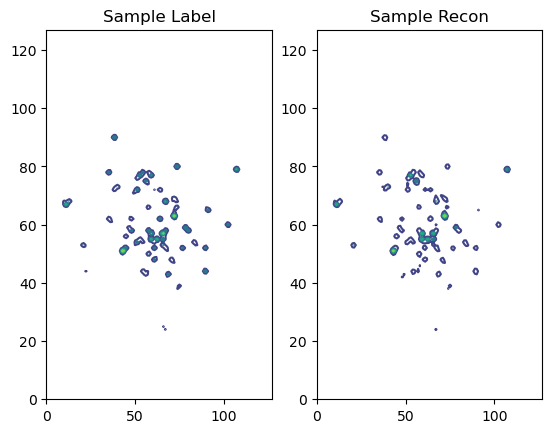

Sample RLNE: 0.15679273


In [ ]:
import nmrglue as ng
import matplotlib.pyplot as plt
import numpy as np
import scipy.io as scio


def compute_rlne(x_true, x_pred):
    x_pred = np.array(x_pred)
    x_true = np.array(x_true)
    l2_error = np.linalg.norm(x_pred - x_true, ord=2)
    l2_true = np.linalg.norm(x_true, ord=2)
    rlne = l2_error / l2_true
    return rlne


def projection_3d(data, projection_type='skyline', iz1=1, izn=512, recon=False):
    if projection_type == 'skyline':
        out = np.max(data[:, iz1 - 1:izn - 1, :], 1)
        out = out / np.max(out)
        return out

    elif projection_type == 'sum':
        out = np.abs(np.sum(data[:, :, iz1 - 1:izn - 1], 2))
        return out


def iz1_izn(data_type):
    if data_type == 'A3DK08':
        N1 = 64
        N2 = 40
        iz1 = 70
        izn = 180
        ppm1 = np.linspace(164.54, 189.07, N1)
        ppm2 = np.linspace(101.83, 134.74, N2)

    return iz1, izn


data_type = 'A3DK08'
iz1, izn = iz1_izn(data_type)

label_path = f'./data/data_3D/{data_type}_label_from_raw.ft'
recon_path = f'./data/data_3D/{data_type}_recon.ft'

dic, data_label = ng.pipe.read(label_path)
dic, data_recon = ng.pipe.read(recon_path)

print('sample label shape:', data_label.shape)
print('sample recon shape:', data_recon.shape)

data_label = np.fft.fftshift(data_label)
data_recon = np.fft.fftshift(data_recon)

data_label = projection_3d(data_label, projection_type='skyline', iz1=iz1, izn=izn)
data_recon = projection_3d(data_recon, projection_type='skyline', iz1=iz1, izn=izn)

print('sample projection shape:', data_label.shape)

plt.figure()
level = 5

plt.subplot(1, 2, 1)
plt.contour(data_label, cmap='viridis', levels=level)
plt.title('Sample Label')

plt.subplot(1, 2, 2)
plt.contour(data_recon, cmap='viridis', levels=level)
plt.title('Sample Recon')

plt.show()

rlne = compute_rlne(data_label, data_recon)
print('Sample RLNE:', rlne)

scio.savemat('./data/A3DK08_sample/label_spec_3D.mat', {'label_spec': data_label})
scio.savemat('./data/A3DK08_sample/recon_spec_3D.mat', {'recon_spec': data_recon})

